# TD — Du repère global à l'angle du genou

1. Construire le repère local d'un segment
2. Exprimer un point dans ce repère
3. Calculer l'angle du genou gauche (deux segments + calibration avec la ROM)

Données : `ROM_S1.c3d` (essai de référence) et `REEL_0008.c3d` (frappe de ballon).

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from pyomeca import Markers
from scipy.spatial.transform import Rotation

marqueurs_rom = Markers.from_c3d("data/ROM_S1.c3d")
marqueurs = Markers.from_c3d("data/REEL_0008.c3d")
temps = np.arange(marqueurs.shape[2]) / marqueurs.attrs["rate"]
print(marqueurs.channel.values.tolist())


def position(essai, nom):
    return essai.sel(channel=nom).values[0:3, :]  # (3, n_frames), en mm


def normaliser(v):
    return v / np.linalg.norm(v)

['RFWT', 'RBWT', 'LFWT', 'LBWT', 'RTHI', 'RKNE', 'RKNI', 'RANE', 'RHEE', 'RANI', 'RTOE', 'LTHI', 'LKNE', 'LKNI', 'LANE', 'LANI', 'LHEE', 'LTOE', 'New 0018', 'New 0019', 'New 0020']


## Rappels

- **Vecteur** : la flèche qui va d'un marqueur à un autre. On l'obtient en soustrayant leurs positions : `B - A`.
- **Norme** : la longueur de cette flèche, `np.linalg.norm(v)`. **Normaliser** : garder la direction et ramener la longueur à 1, `v / np.linalg.norm(v)`.
- **Produit vectoriel** `np.cross(a, b)` : avec deux flèches, il en fabrique une 3e, à angle droit des deux. Si on inverse l'ordre, elle pointe dans l'autre sens.
- **Produit scalaire** `np.dot(a, b)` : un nombre qui vaut 0 quand deux flèches sont à angle droit.

Exemples :

In [2]:
A = np.array([1, 1, 0])
B = np.array([5, 4, 0])
v = B - A
print("v =", v, "  norme =", np.linalg.norm(v), "  normalisé =", normaliser(v))

a = np.array([1, 0, 0])
b = np.array([0, 1, 0])
print("a.b =", np.dot(a, b), "(perpendiculaires)")
print("a x b =", np.cross(a, b), "  b x a =", np.cross(b, a))

v = [4 3 0]   norme = 5.0   normalisé = [0.8 0.6 0. ]
a.b = 0 (perpendiculaires)
a x b = [0 0 1]   b x a = [ 0  0 -1]


## Étape 1 — Repère local du bassin

3 marqueurs non alignés : `RFWT`, `LFWT` (ASIS) et `RBWT` (PSIS droite).

- origine : milieu de `RFWT` et `LFWT`
- z (droite) : `RFWT − LFWT`, normalisé
- y (haut) : `z × (origine − RBWT)`, normalisé
- x (avant) : `y × z`
- `R = [x | y | z]` (axes en colonnes)

Pourquoi le produit vectoriel ? `RFWT − LFWT` donne un premier axe (z). `origine − RBWT` pointe à peu près vers l'avant, mais pas exactement perpendiculaire à z. Le produit vectoriel des deux donne un axe perpendiculaire aux deux (y, vers le haut). Un deuxième produit vectoriel `y × z` donne le dernier axe (x), perpendiculaire à y et à z. On obtient ainsi 3 axes perpendiculaires de longueur 1.

`det(R) = +1` vérifie que le repère est « direct » (pas inversé comme dans un miroir).

Autre manière : les articles ISB (Wu et al. 2002, 2005) définissent un repère propre à chaque segment à partir de points anatomiques précis.

In [3]:
def repere_bassin(rfwt, lfwt, rbwt):
    origine = (rfwt + lfwt) / 2
    z = normaliser(rfwt - lfwt)
    y = normaliser(np.cross(z, origine - rbwt))
    x = np.cross(y, z)
    return origine, np.column_stack((x, y, z))


rfwt, lfwt, rbwt, lbwt = [position(marqueurs, nom) for nom in ["RFWT", "LFWT", "RBWT", "LBWT"]]
origine, R = repere_bassin(rfwt[:, 0], lfwt[:, 0], rbwt[:, 0])
print(np.round(R, 3))
print("det(R) =", round(np.linalg.det(R), 3))

[[-0.358 -0.148  0.922]
 [ 0.731  0.57   0.375]
 [-0.581  0.808 -0.096]]
det(R) = 1.0


## Étape 2 — Exprimer un point dans le repère du bassin

`p_local = Rᵀ · (p_global − origine)`

Deux opérations :
1. `p_global − origine` : le vecteur qui va de l'origine du bassin au point (on mesure le point depuis le bassin).
2. `Rᵀ · (...)` : `Rᵀ` est la transposée de `R` (lignes ↔ colonnes), donc ses lignes sont les axes x, y, z. Multiplier par `Rᵀ` revient à faire 3 produits scalaires : la longueur du vecteur le long de x, le long de y et le long de z. Ce sont les coordonnées du point dans le repère du bassin.

On l'applique à `LBWT`, qui n'a pas servi à construire le repère (marqueur témoin). Le bassin étant rigide, ses coordonnées locales doivent rester presque constantes pendant la frappe.

écart-type de LBWT en local (mm) : [1.5 1.7 2.9]


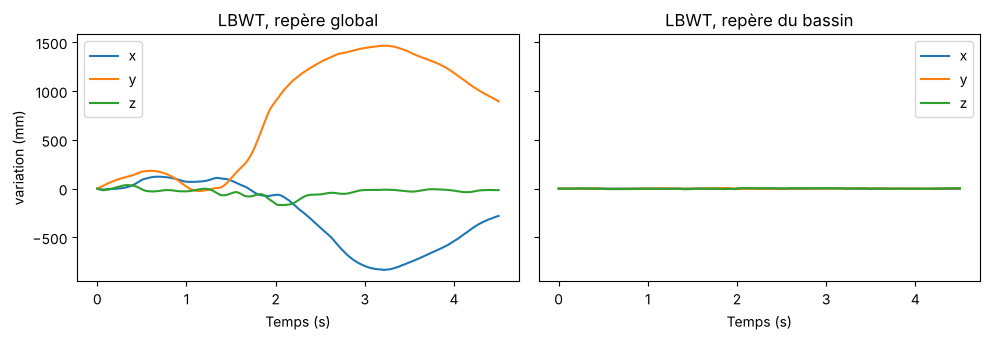

In [4]:
def vers_repere_local(p_global, origine, R):
    return R.T @ (p_global - origine)


n_frames = rfwt.shape[1]
lbwt_local = np.zeros((3, n_frames))
for i in range(n_frames):
    origine_i, R_i = repere_bassin(rfwt[:, i], lfwt[:, i], rbwt[:, i])
    lbwt_local[:, i] = vers_repere_local(lbwt[:, i], origine_i, R_i)

print("écart-type de LBWT en local (mm) :", np.round(lbwt_local.std(axis=1), 1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for k, nom in enumerate(["x", "y", "z"]):
    axes[0].plot(temps, lbwt[k] - lbwt[k, 0], label=nom)
    axes[1].plot(temps, lbwt_local[k] - lbwt_local[k, 0], label=nom)
axes[0].set_title("LBWT, repère global")
axes[1].set_title("LBWT, repère du bassin")
axes[0].set_ylabel("variation (mm)")
for ax in axes:
    ax.set_xlabel("Temps (s)")
    ax.legend()
plt.tight_layout()
plt.show()

## Étape 3 — Angle du genou gauche

Même recette pour la cuisse (proximal) et la jambe (distal), avec x avant, y haut, z vers la droite :

- cuisse (`LTHI`, `LKNE`, `LKNI`) : origine au centre du genou, z = `LKNI − LKNE`, x = `(LTHI − origine) × z`, y = `z × x`
- jambe (`LKNE`, `LKNI`, `LANE`, `LANI`) : origine au centre de la cheville, z = `LANI − LANE`, x = `(centre genou − origine) × z`, y = `z × x`

Puis, à chaque image : `R_rel = R_cuisseᵀ · R_jambe`. C'est la même idée que l'étape 2, mais pour un repère entier au lieu d'un point : on exprime les 3 axes de la jambe dans le repère de la cuisse. Si la jambe est orientée exactement comme la cuisse, `R_rel` est la matrice identité et les 3 angles valent 0.

`R_rel` est ensuite décomposé en une **séquence de Cardan** : 3 rotations faites l'une après l'autre, autour de 3 axes différents, dans un ordre fixé (ici Z-X-Y, Grood & Suntay 1983). L'ordre compte : changer l'ordre change les angles obtenus. Les 3 rotations : d'abord autour de z (flexion-extension), puis autour du x déjà tourné (abduction-adduction), puis autour du y déjà tourné (rotation interne-externe). Dans scipy : `as_euler("ZXY")`, en **majuscules** (rotations autour des axes qui ont déjà tourné). Genou gauche : × (−1) pour avoir flexion +, abduction +, rotation interne +.

In [5]:
def repere_cuisse(thi, kne, kni):
    origine = (kne + kni) / 2
    z = normaliser(kni - kne)
    x = normaliser(np.cross(thi - origine, z))
    return np.column_stack((x, np.cross(z, x), z))


def repere_jambe(kne, kni, ane, ani):
    origine = (ane + ani) / 2
    z = normaliser(ani - ane)
    x = normaliser(np.cross((kne + kni) / 2 - origine, z))
    return np.column_stack((x, np.cross(z, x), z))


def angles_genou(essai):
    thi, kne, kni, ane, ani = [position(essai, nom) for nom in ["LTHI", "LKNE", "LKNI", "LANE", "LANI"]]
    angles = np.zeros((3, thi.shape[1]))
    for i in range(thi.shape[1]):
        R_cuisse = repere_cuisse(thi[:, i], kne[:, i], kni[:, i])
        R_jambe = repere_jambe(kne[:, i], kni[:, i], ane[:, i], ani[:, i])
        R_rel = R_cuisse.T @ R_jambe
        angles[:, i] = -Rotation.from_matrix(R_rel).as_euler("ZXY", degrees=True)
    return angles


angles = angles_genou(marqueurs)

### Calibration : à quoi sert la ROM ?

Sujet debout, jambe tendue, on s'attendrait à des angles nuls. Ce n'est pas le cas : les marqueurs ne sont pas posés exactement sur les repères anatomiques, on n'a pas de centre de hanche et la peau glisse sur l'os. Les axes de la cuisse et de la jambe sont donc légèrement décalés par rapport à l'anatomie.

Ce décalage reste le même pendant tout le mouvement. L'essai de référence (`ROM_S1`) sert à le mesurer : on calcule les angles du genou à l'instant où le sujet bouge le moins. On le retire ensuite à toute la frappe, comme on fait la tare d'une balance :

`angle calibré = angle brut − angle de la ROM`

Après calibration, 0° veut dire « comme en position de référence » (principe de la calibration anatomique CAST, Cappozzo et al. 1995). Pour vos captures : enregistrez toujours un essai statique en position de référence, avec les mêmes marqueurs.

angles de référence (deg) : [-14.4   4.5  -3.1]


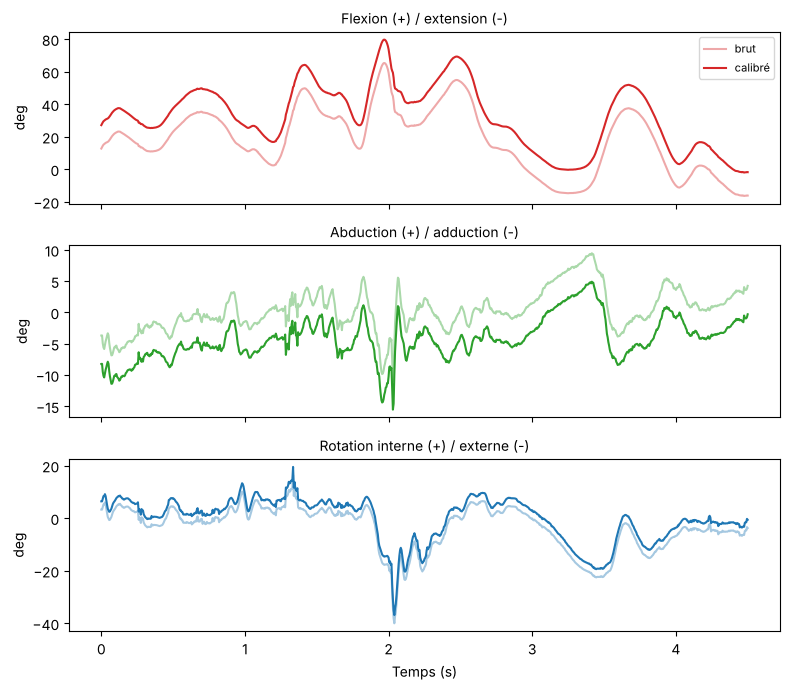

In [6]:
angles_rom = angles_genou(marqueurs_rom)

genou_rom = np.vstack([position(marqueurs_rom, nom) for nom in ["LTHI", "LKNE", "LKNI", "LANE", "LANI"]])
vitesse = np.convolve(np.linalg.norm(np.diff(genou_rom, axis=1), axis=0), np.ones(50) / 50, mode="same")
angles_ref = angles_rom[:, np.argmin(vitesse)]
angles_cal = angles - angles_ref[:, None]
print("angles de référence (deg) :", np.round(angles_ref, 1))

fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
titres = ["Flexion (+) / extension (-)", "Abduction (+) / adduction (-)", "Rotation interne (+) / externe (-)"]
for k, couleur in enumerate(["tab:red", "tab:green", "tab:blue"]):
    axes[k].plot(temps, angles[k], color=couleur, alpha=0.4, label="brut")
    axes[k].plot(temps, angles_cal[k], color=couleur, label="calibré")
    axes[k].set_title(titres[k], fontsize=10)
    axes[k].set_ylabel("deg")
axes[0].legend(fontsize=8)
axes[-1].set_xlabel("Temps (s)")
plt.tight_layout()
plt.show()

## À vous

Adaptez cette démarche à l'articulation et aux données de votre groupe : un repère par segment, un essai de référence, `R_rel = R_proximalᵀ · R_distal`, la séquence adaptée (Wu et al. 2002 / 2005), et les signes à vérifier à droite et à gauche.